In [3]:
# CELL 1 – Imports (Fixed Version)
import os, math, warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import __version__ as sklearn_version
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

print("All required libraries imported successfully.")
print("Pandas version:", pd.__version__, "Scikit-learn version:", sklearn_version)
print("-" * 50)

All required libraries imported successfully.
Pandas version: 2.2.2 Scikit-learn version: 1.4.2
--------------------------------------------------


In [4]:
# CELL 2 – Load Dataset
csv_path = "medical_diagnostic_dataset.csv"
df = pd.read_csv(csv_path)
print("Dataset loaded:", csv_path)
print("Shape:", df.shape)
print("\nDataset Overview:")
print("-" * 50)
print(f"Total samples: {df.shape[0]}")
print(f"Total features: {df.shape[1]}")
print(f"Target variable: 'Outcome' (0 = No Diabetes, 1 = Diabetes)")
display(df.head())

Dataset loaded: medical_diagnostic_dataset.csv
Shape: (300, 7)

Dataset Overview:
--------------------------------------------------
Total samples: 300
Total features: 7
Target variable: 'Outcome' (0 = No Diabetes, 1 = Diabetes)


,Age,BMI,Glucose,BloodPressure,Insulin,SkinThickness,Outcome
0,59,34.3,119,71,137,9,0
1,72,24.3,167,75,43,24,0
2,49,26.8,151,77,151,12,1
3,35,36.6,99,98,209,47,1
4,63,32.6,148,98,240,16,1


In [5]:
# CELL 3 – Data Info
info_df = pd.DataFrame({'dtypes': df.dtypes.astype(str), 'missing': df.isnull().sum()})
print("Data Types and Missing Values Analysis:")
print("-" * 50)
display(info_df)

# Additional statistics
print("\nStatistical Summary:")
print("-" * 50)
display(df.describe().T)

Data Types and Missing Values Analysis:
--------------------------------------------------


,dtypes,missing
Age,int64,0
BMI,float64,0
Glucose,int64,0
BloodPressure,int64,0
Insulin,int64,0
SkinThickness,int64,0
Outcome,int64,0



Statistical Summary:
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Age,300.0,49.910000,17.402626,21.0,35.00,49.5,64.000,79.0
BMI,300.0,29.701000,6.382839,9.8,25.55,30.0,34.325,49.1
Glucose,300.0,132.906667,37.152735,70.0,102.75,132.0,164.000,199.0
BloodPressure,300.0,83.860000,19.990309,50.0,66.00,84.0,102.000,119.0
Insulin,300.0,150.553333,86.162252,16.0,72.00,154.0,228.000,299.0
SkinThickness,300.0,26.786667,13.186639,5.0,15.00,27.0,39.000,49.0
Outcome,300.0,0.543333,0.498951,0.0,0.00,1.0,1.000,1.0


Target Analysis:
--------------------------------------------------
Target column: Outcome


Outcome
1    163
0    137
Name: count, dtype: int64


Class Balance:
  Class 0 (No Diabetes): 137 samples (45.7%)
  Class 1 (Diabetes): 163 samples (54.3%)
  Imbalance Ratio: 1.19:1


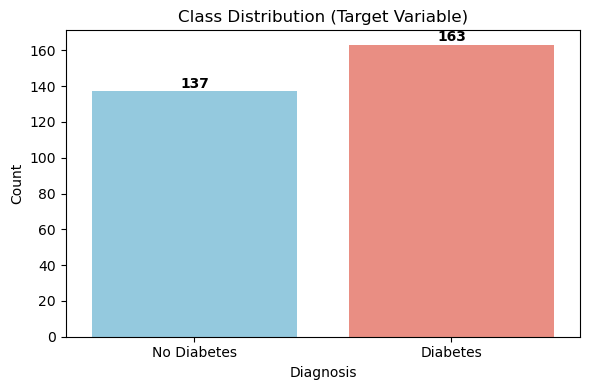

In [6]:
# CELL 4 – Target Distribution
target_col = 'Outcome'
print("Target Analysis:")
print("-" * 50)
print("Target column:", target_col)

class_dist = df[target_col].value_counts()
display(class_dist)

print(f"\nClass Balance:")
print(f"  Class 0 (No Diabetes): {class_dist[0]} samples ({class_dist[0]/len(df)*100:.1f}%)")
print(f"  Class 1 (Diabetes): {class_dist[1]} samples ({class_dist[1]/len(df)*100:.1f}%)")
print(f"  Imbalance Ratio: {max(class_dist)/min(class_dist):.2f}:1")

# Plot
vc = df[target_col].value_counts().sort_index()
plt.figure(figsize=(6,4))
sns.barplot(x=['No Diabetes', 'Diabetes'], y=vc.values, palette=['skyblue', 'salmon'])
plt.title("Class Distribution (Target Variable)")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
for i, v in enumerate(vc.values):
    plt.text(i, v + 2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

Numerical Feature Analysis:
--------------------------------------------------
Features: ['Age', 'BMI', 'Glucose', 'BloodPressure', 'Insulin', 'SkinThickness', 'Outcome']


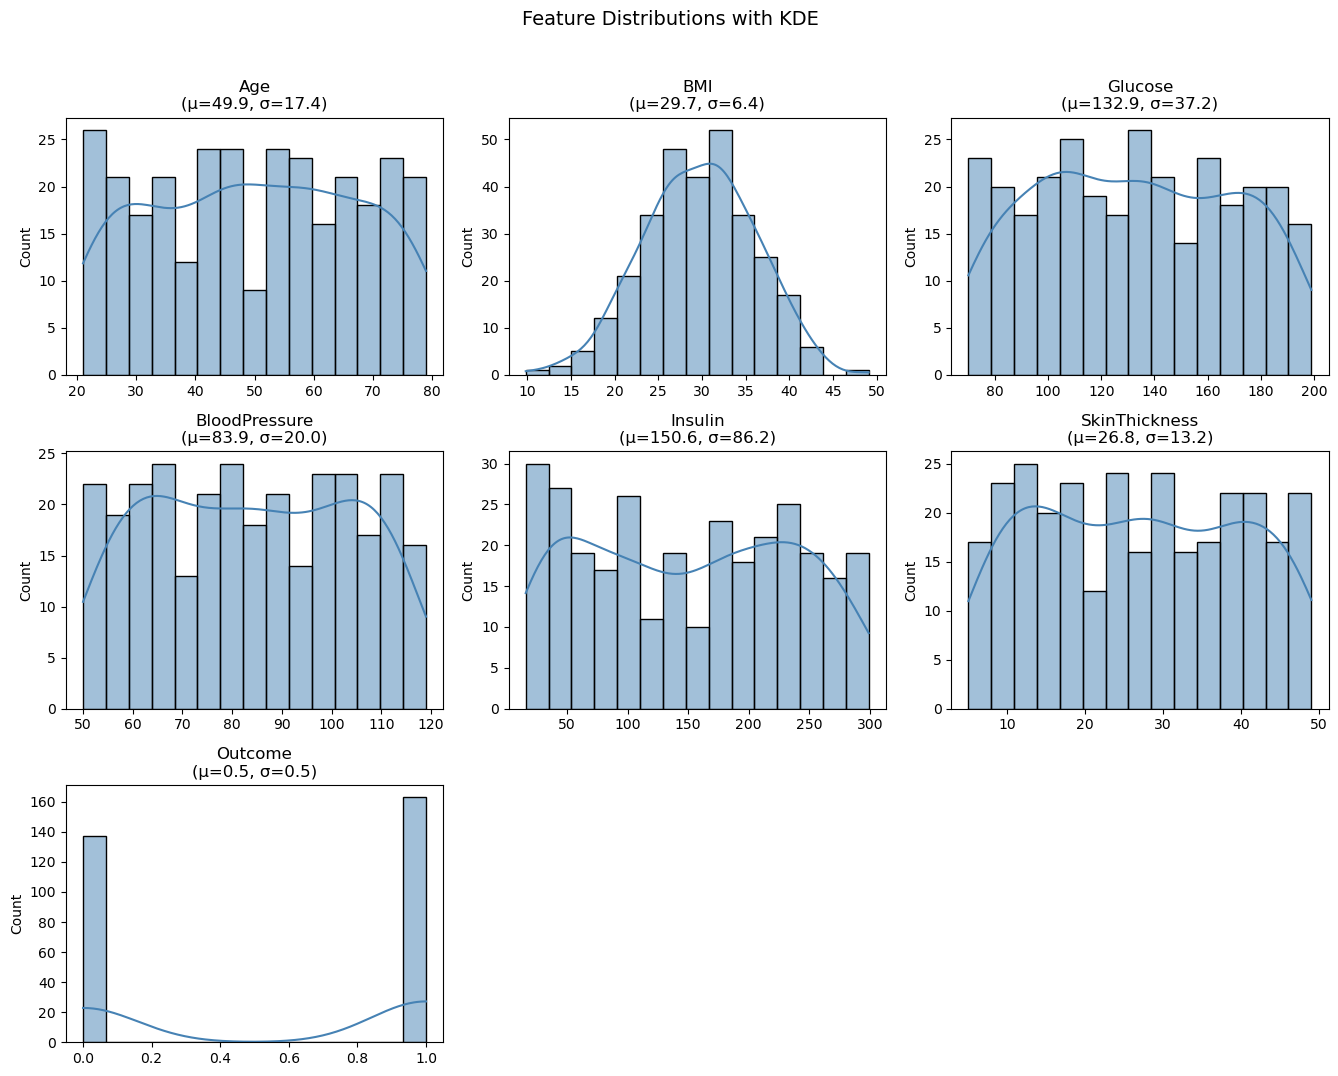

In [8]:
# CELL 5 – Numeric Feature Distributions
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numerical Feature Analysis:")
print("-" * 50)
print("Features:", num_cols)

ncols = 3
nrows = math.ceil(len(num_cols)/ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.5*nrows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), ax=axes[i], kde=True, color='steelblue', bins=15)
    axes[i].set_title(f"{col}\n(μ={df[col].mean():.1f}, σ={df[col].std():.1f})")
    axes[i].set_xlabel("")
for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.suptitle("Feature Distributions with KDE", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Feature Correlation Analysis:
--------------------------------------------------
No strong correlations detected (all |r| < 0.3)


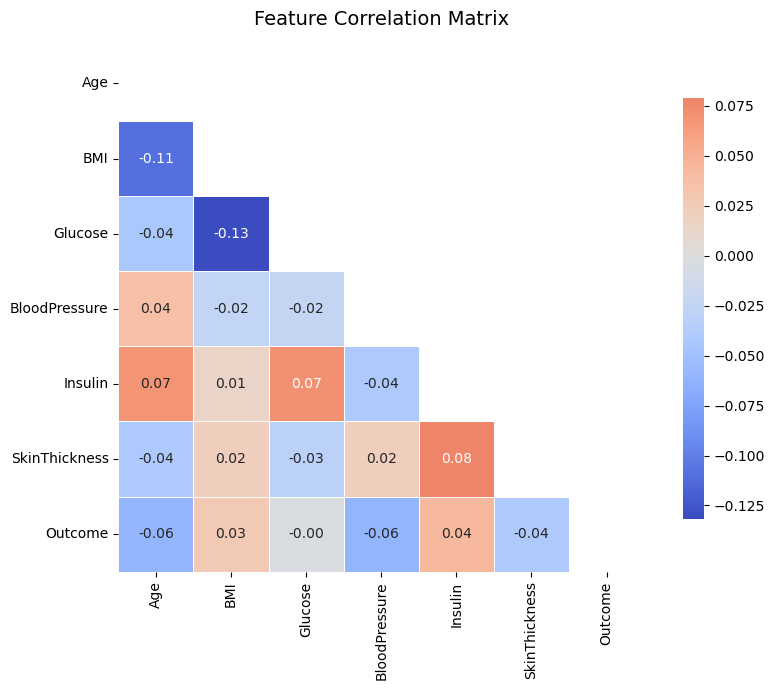

In [9]:
# CELL 6 – Correlation Analysis
corr = df[num_cols].corr()
print("Feature Correlation Analysis:")
print("-" * 50)

# Identify strong correlations
strong_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.3:  # Moderate correlation threshold
            strong_corr.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))

if strong_corr:
    print("Notable Correlations (|r| > 0.3):")
    for feat1, feat2, r_val in strong_corr:
        print(f"  {feat1} ↔ {feat2}: {r_val:.3f}")
else:
    print("No strong correlations detected (all |r| < 0.3)")

# Visualize
plt.figure(figsize=(9,7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", mask=mask, 
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [10]:
# CELL 7 – Preprocessing
X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

print("Preprocessing Pipeline:")
print("-" * 50)
print("1. Feature-Target Separation")
print(f"   Features (X): {X.shape}")
print(f"   Target (y): {y.shape}")

# Handle numeric only (no categorical in this dataset)
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
print(f"\n2. Numerical Features: {num_cols}")

# Impute median (though no missing values, for robustness)
print("\n3. Imputation Strategy:")
print("   Using SimpleImputer(strategy='median') for all features")
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)
X_imputed = pd.DataFrame(X_imputed, columns=X.columns)
print("   Imputation complete (no actual missing values in this dataset)")

# Standard scaling
print("\n4. Feature Scaling:")
print("   Using StandardScaler (z-score normalization)")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
print("   Scaling complete - features now have μ=0, σ=1")

# Display sample
print("\n5. Preprocessed Sample (first 3 rows):")
display(pd.DataFrame(X_scaled, columns=X.columns).head(3))

Preprocessing Pipeline:
--------------------------------------------------
1. Feature-Target Separation
   Features (X): (300, 6)
   Target (y): (300,)

2. Numerical Features: ['Age', 'BMI', 'Glucose', 'BloodPressure', 'Insulin', 'SkinThickness']

3. Imputation Strategy:
   Using SimpleImputer(strategy='median') for all features
   Imputation complete (no actual missing values in this dataset)

4. Feature Scaling:
   Using StandardScaler (z-score normalization)
   Scaling complete - features now have μ=0, σ=1

5. Preprocessed Sample (first 3 rows):


,Age,BMI,Glucose,BloodPressure,Insulin,SkinThickness
0,0.523208,0.721730,-0.374936,-0.644387,-0.157563,-1.351094
1,1.271470,-0.847589,0.919187,-0.443955,-1.250351,-0.211678
2,-0.052378,-0.455259,0.487812,-0.343740,0.005193,-1.123211


In [11]:
# CELL 8 – Train-Test Split with CV Setup
print("Data Splitting Strategy:")
print("-" * 50)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test Set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Feature Dimension: {X_train.shape[1]}")

print("\nClass Distribution Preservation:")
print(f"  Training - Class 0: {np.sum(y_train==0)} ({np.sum(y_train==0)/len(y_train)*100:.1f}%)")
print(f"  Training - Class 1: {np.sum(y_train==1)} ({np.sum(y_train==1)/len(y_train)*100:.1f}%)")
print(f"  Test - Class 0: {np.sum(y_test==0)} ({np.sum(y_test==0)/len(y_test)*100:.1f}%)")
print(f"  Test - Class 1: {np.sum(y_test==1)} ({np.sum(y_test==1)/len(y_test)*100:.1f}%)")

# Setup cross-validation
print("\n6. Cross-Validation Setup:")
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"   Using StratifiedKFold with {cv_strategy.n_splits} folds")
print("   Preserves class distribution in each fold")

Data Splitting Strategy:
--------------------------------------------------
Training Set: 240 samples (80.0%)
Test Set: 60 samples (20.0%)
Feature Dimension: 6

Class Distribution Preservation:
  Training - Class 0: 110 (45.8%)
  Training - Class 1: 130 (54.2%)
  Test - Class 0: 27 (45.0%)
  Test - Class 1: 33 (55.0%)

6. Cross-Validation Setup:
   Using StratifiedKFold with 5 folds
   Preserves class distribution in each fold


Baseline Model Implementation:
--------------------------------------------------
Model Configurations:
  DecisionTree: DecisionTreeClassifier
  GaussianNB: GaussianNB
  KNN: KNeighborsClassifier
  MLP: MLPClassifier

Cross-Validation Performance (ROC-AUC):
----------------------------------------
DecisionTree    | Mean AUC: 0.4727 (±0.0498)
                | Fold scores: ['0.451', '0.442', '0.558', '0.497', '0.416']
GaussianNB      | Mean AUC: 0.5101 (±0.0453)
                | Fold scores: ['0.470', '0.598', '0.486', '0.505', '0.491']
KNN             | Mean AUC: 0.4928 (±0.0816)
                | Fold scores: ['0.636', '0.479', '0.448', '0.509', '0.392']
MLP             | Mean AUC: 0.5245 (±0.0520)
                | Fold scores: ['0.586', '0.477', '0.465', '0.586', '0.509']

Training Models on Full Training Set...
  ✓ Trained: DecisionTree
  ✓ Trained: GaussianNB
  ✓ Trained: KNN
  ✓ Trained: MLP


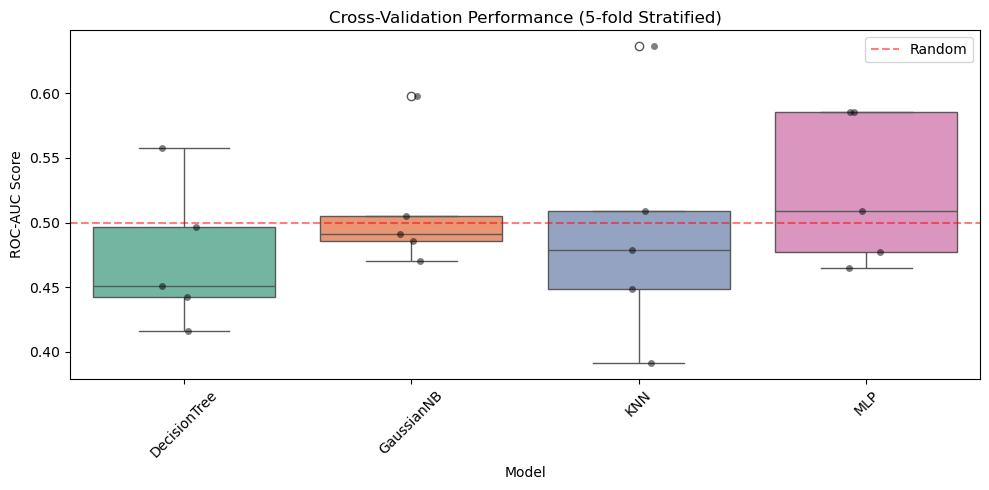

In [12]:
# CELL 9 – Baseline Models with CV Evaluation
print("Baseline Model Implementation:")
print("-" * 50)

models = {
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'GaussianNB': GaussianNB(),
    'KNN': KNeighborsClassifier(),
    'MLP': MLPClassifier(max_iter=500, random_state=42, hidden_layer_sizes=(50,))
}

print("Model Configurations:")
for name, model in models.items():
    print(f"  {name}: {model.__class__.__name__}")

print("\nCross-Validation Performance (ROC-AUC):")
print("-" * 40)

cv_scores = {}
for name, model in models.items():
    # Perform cross-validation
    scores = cross_val_score(model, X_train, y_train, 
                            cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
    cv_scores[name] = scores
    
    print(f"{name:15s} | Mean AUC: {scores.mean():.4f} (±{scores.std():.4f})")
    print(f"{' ':15s} | Fold scores: {['%.3f' % s for s in scores]}")

print("\nTraining Models on Full Training Set...")
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"  ✓ Trained: {name}")

# Visualize CV performance
plt.figure(figsize=(10, 5))
cv_data = []
for name, scores in cv_scores.items():
    cv_data.extend([(name, i+1, score) for i, score in enumerate(scores)])

cv_df = pd.DataFrame(cv_data, columns=['Model', 'Fold', 'ROC-AUC'])
sns.boxplot(data=cv_df, x='Model', y='ROC-AUC', palette='Set2')
sns.stripplot(data=cv_df, x='Model', y='ROC-AUC', color='black', size=5, alpha=0.5)
plt.title("Cross-Validation Performance (5-fold Stratified)")
plt.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
plt.ylabel("ROC-AUC Score")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# CELL 10 – Hyperparameter Tuning with Cross-Validation
print("Hyperparameter Tuning:")
print("-" * 50)
print("Models selected for tuning: Random Forest and SVM")
print(f"Validation: {cv_strategy.n_splits}-fold Stratified Cross-Validation")
print("Optimization metric: ROC-AUC\n")

# Random Forest Tuning
print("1. Random Forest Tuning")
print("   Parameter Grid:")
print("   - n_estimators: [50, 100, 150]")
print("   - max_depth: [None, 5, 10]")
print("   - min_samples_split: [2, 5]")

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        'n_estimators': [50, 100, 150],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5]
    },
    cv=cv_strategy, scoring='roc_auc', n_jobs=-1, verbose=0
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

print(f"   Best Parameters: {rf_grid.best_params_}")
print(f"   Best CV Score: {rf_grid.best_score_:.4f}")
print(f"   Total Combinations: {len(rf_grid.cv_results_['params'])}")
print(f"   Training Time: {rf_grid.refit_time_:.2f}s")

# SVM Tuning
print("\n2. Support Vector Machine Tuning")
print("   Parameter Grid:")
print("   - C: [0.1, 0.5, 1, 2]")
print("   - kernel: ['linear', 'rbf']")
print("   - gamma: ['scale', 'auto'] (for rbf)")

svm_grid = GridSearchCV(
    SVC(probability=True, random_state=42),
    {
        'C': [0.1, 0.5, 1, 2],
        'kernel': ['linear', 'rbf'],
        'gamma': ['scale', 'auto']
    },
    cv=cv_strategy, scoring='roc_auc', n_jobs=-1, verbose=0
)
svm_grid.fit(X_train, y_train)
best_svm = svm_grid.best_estimator_

print(f"   Best Parameters: {svm_grid.best_params_}")
print(f"   Best CV Score: {svm_grid.best_score_:.4f}")
print(f"   Total Combinations: {len(svm_grid.cv_results_['params'])}")
print(f"   Training Time: {svm_grid.refit_time_:.2f}s")

# Compare tuning results
print("\n3. Tuning Results Summary")
print("-" * 30)
results_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'SVM'],
    'Best CV AUC': [rf_grid.best_score_, svm_grid.best_score_],
    'Best Parameters': [str(rf_grid.best_params_), str(svm_grid.best_params_)],
    'Search Space Size': [len(rf_grid.cv_results_['params']), 
                         len(svm_grid.cv_results_['params'])]
})
display(results_comparison)

Hyperparameter Tuning:
--------------------------------------------------
Models selected for tuning: Random Forest and SVM
Validation: 5-fold Stratified Cross-Validation
Optimization metric: ROC-AUC

1. Random Forest Tuning
   Parameter Grid:
   - n_estimators: [50, 100, 150]
   - max_depth: [None, 5, 10]
   - min_samples_split: [2, 5]
   Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
   Best CV Score: 0.4787
   Total Combinations: 18
   Training Time: 0.44s

2. Support Vector Machine Tuning
   Parameter Grid:
   - C: [0.1, 0.5, 1, 2]
   - kernel: ['linear', 'rbf']
   - gamma: ['scale', 'auto'] (for rbf)
   Best Parameters: {'C': 0.5, 'gamma': 'scale', 'kernel': 'linear'}
   Best CV Score: 0.5154
   Total Combinations: 16
   Training Time: 0.05s

3. Tuning Results Summary
------------------------------


,Model,Best CV AUC,Best Parameters,Search Space Size
0,Random Forest,0.478671,"{'max_depth': None, 'min_samples_split': 2, 'n...",18
1,SVM,0.515385,"{'C': 0.5, 'gamma': 'scale', 'kernel': 'linear'}",16


In [14]:
# CELL 11 – Comprehensive Evaluation
print("Final Model Evaluation:")
print("-" * 50)
print("Evaluating 6 models (4 baseline + 2 tuned) on test set")
print(f"Test Set Size: {len(y_test)} samples\n")

models_final = {
    'DecisionTree': models['DecisionTree'],
    'GaussianNB': models['GaussianNB'],
    'KNN': models['KNN'],
    'MLP': models['MLP'],
    'RandomForest': best_rf,
    'SVM': best_svm
}

results = []
cv_results = []  # Store CV metrics

print("Performance Metrics:")
print("-" * 80)

for name, model in models_final.items():
    # Get cross-validation scores if available
    if name in ['RandomForest', 'SVM']:
        if name == 'RandomForest':
            cv_auc = rf_grid.best_score_
        else:
            cv_auc = svm_grid.best_score_
    else:
        # Calculate CV scores for baseline models
        cv_scores = cross_val_score(model, X_train, y_train, 
                                   cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
        cv_auc = cv_scores.mean()
    
    # Test set evaluation
    y_pred = model.predict(X_test)
    
    # Get probabilities for AUC calculation
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:,1]
    else:
        if hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
            y_proba = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)
        else:
            y_proba = np.zeros_like(y_pred, dtype=float)
    
    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)
    
    results.append([name, acc, prec, rec, f1, auc, cv_auc])
    
    # Print results
    print(f"{name:15s} | Test AUC: {auc:.4f} | CV AUC: {cv_auc:.4f} | "
          f"Accuracy: {acc:.4f} | F1: {f1:.4f}")

# Create results DataFrame
results_df = pd.DataFrame(results, 
                         columns=['Model', 'Accuracy', 'Precision', 'Recall', 
                                 'F1', 'Test_ROC_AUC', 'CV_ROC_AUC'])

print("\n" + "="*80)
print("COMPARATIVE PERFORMANCE SUMMARY")
print("="*80)
display(results_df.sort_values('Test_ROC_AUC', ascending=False))

Final Model Evaluation:
--------------------------------------------------
Evaluating 6 models (4 baseline + 2 tuned) on test set
Test Set Size: 60 samples

Performance Metrics:
--------------------------------------------------------------------------------
DecisionTree    | Test AUC: 0.4613 | CV AUC: 0.4727 | Accuracy: 0.4667 | F1: 0.5152
GaussianNB      | Test AUC: 0.4299 | CV AUC: 0.5101 | Accuracy: 0.4500 | F1: 0.5600
KNN             | Test AUC: 0.4355 | CV AUC: 0.4928 | Accuracy: 0.4167 | F1: 0.4776
MLP             | Test AUC: 0.4377 | CV AUC: 0.5245 | Accuracy: 0.4667 | F1: 0.5789
RandomForest    | Test AUC: 0.4422 | CV AUC: 0.4787 | Accuracy: 0.4500 | F1: 0.5352
SVM             | Test AUC: 0.5859 | CV AUC: 0.5154 | Accuracy: 0.4833 | F1: 0.5507

COMPARATIVE PERFORMANCE SUMMARY


,Model,Accuracy,Precision,Recall,F1,Test_ROC_AUC,CV_ROC_AUC
5,SVM,0.483333,0.527778,0.575758,0.550725,0.585859,0.515385
0,DecisionTree,0.466667,0.515152,0.515152,0.515152,0.461279,0.472727
4,RandomForest,0.450000,0.500000,0.575758,0.535211,0.442200,0.478671
3,MLP,0.466667,0.511628,0.666667,0.578947,0.437710,0.524476
2,KNN,0.416667,0.470588,0.484848,0.477612,0.435466,0.492832
1,GaussianNB,0.450000,0.500000,0.636364,0.560000,0.429854,0.510140


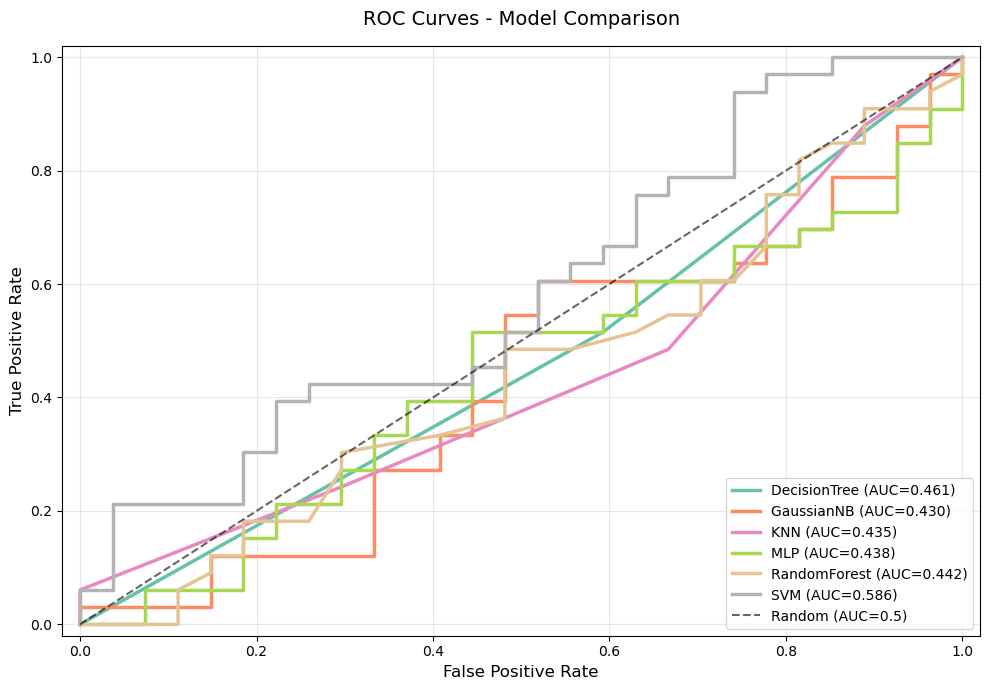


🎯 Best Performing Model: SVM with Test AUC = 0.5859


In [15]:
# CELL 12 – ROC Curves Comparison
plt.figure(figsize=(10, 7))
colors = plt.cm.Set2(np.linspace(0, 1, len(models_final)))

for (name, model), color in zip(models_final.items(), colors):
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:,1]
    else:
        if hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
            y_proba = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)
        else:
            continue
    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.3f})", 
             color=color, linewidth=2.5)

# Random classifier line
plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random (AUC=0.5)')

plt.title("ROC Curves - Model Comparison", fontsize=14, pad=15)
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

# Highlight best model
best_model_name = results_df.loc[results_df['Test_ROC_AUC'].idxmax(), 'Model']
best_model_auc = results_df.loc[results_df['Test_ROC_AUC'].idxmax(), 'Test_ROC_AUC']
print(f"\n🎯 Best Performing Model: {best_model_name} with Test AUC = {best_model_auc:.4f}")

Confusion Matrices Analysis:
--------------------------------------------------
Comparing predictions across all models



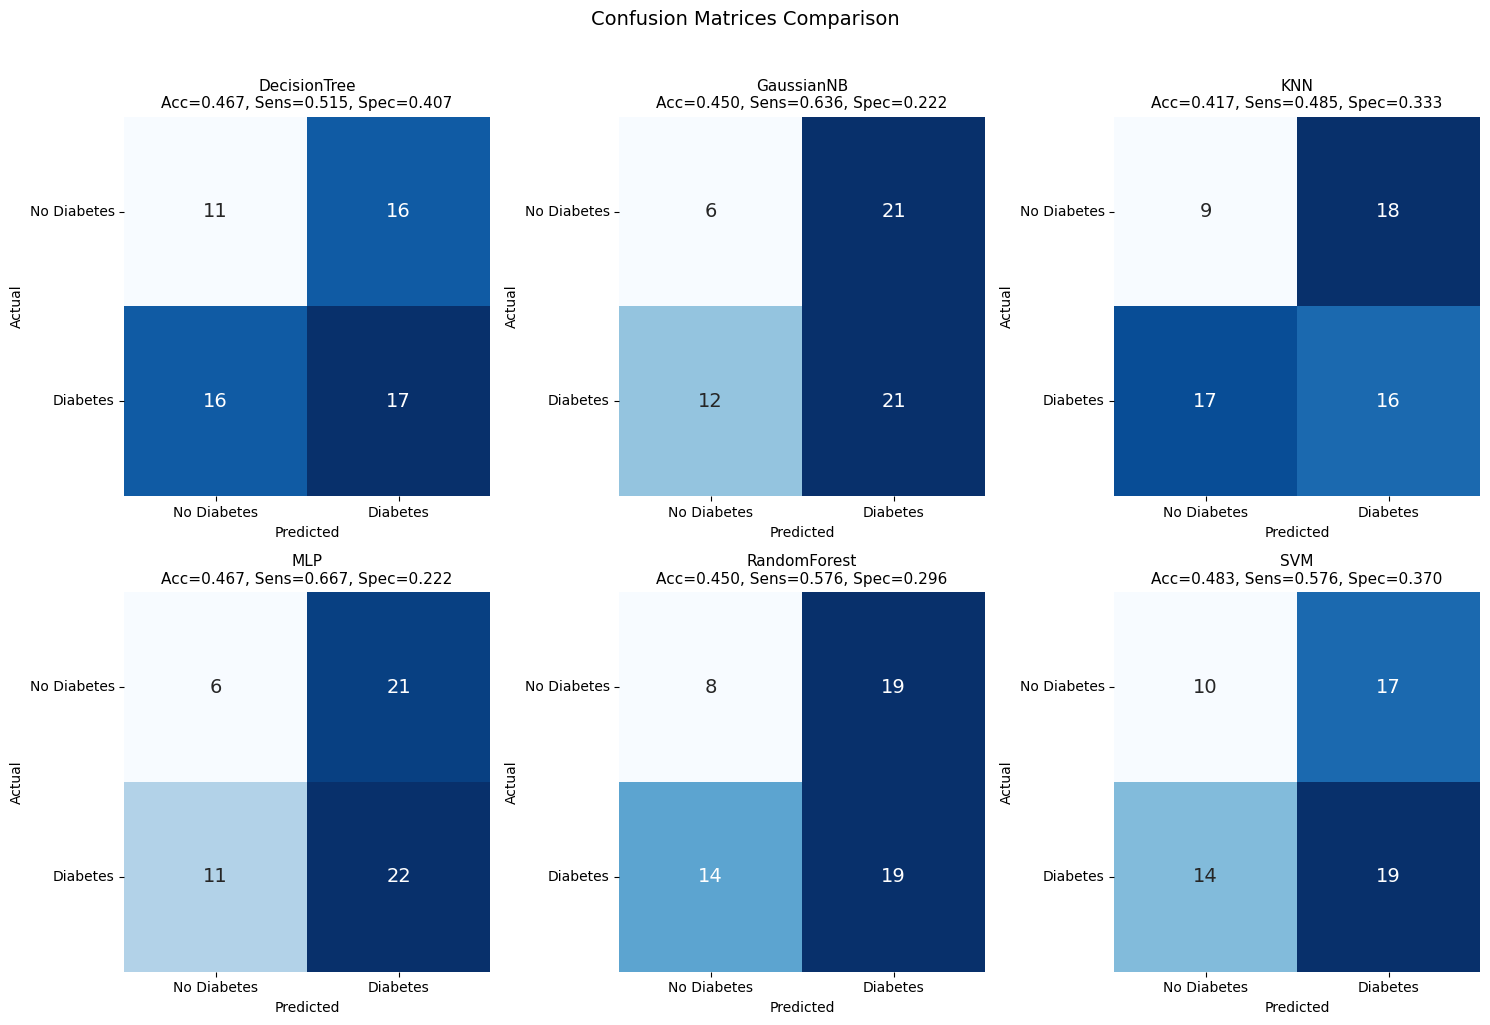


Classification Performance Summary:
----------------------------------------

DecisionTree:
  Class 0 (No Diabetes): Precision=0.407, Recall=0.407, F1=0.407
  Class 1 (Diabetes): Precision=0.515, Recall=0.515, F1=0.515

GaussianNB:
  Class 0 (No Diabetes): Precision=0.333, Recall=0.222, F1=0.267
  Class 1 (Diabetes): Precision=0.500, Recall=0.636, F1=0.560

KNN:
  Class 0 (No Diabetes): Precision=0.346, Recall=0.333, F1=0.340
  Class 1 (Diabetes): Precision=0.471, Recall=0.485, F1=0.478

MLP:
  Class 0 (No Diabetes): Precision=0.353, Recall=0.222, F1=0.273
  Class 1 (Diabetes): Precision=0.512, Recall=0.667, F1=0.579

RandomForest:
  Class 0 (No Diabetes): Precision=0.364, Recall=0.296, F1=0.327
  Class 1 (Diabetes): Precision=0.500, Recall=0.576, F1=0.535

SVM:
  Class 0 (No Diabetes): Precision=0.417, Recall=0.370, F1=0.392
  Class 1 (Diabetes): Precision=0.528, Recall=0.576, F1=0.551


In [16]:
# CELL 13 – Confusion Matrices Grid
print("Confusion Matrices Analysis:")
print("-" * 50)
print("Comparing predictions across all models\n")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_final.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    # Calculate metrics from confusion matrix
    tn, fp, fn, tp = cm.ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Plot
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
                ax=ax, annot_kws={'size': 14})
    ax.set_title(f"{name}\nAcc={accuracy:.3f}, Sens={sensitivity:.3f}, Spec={specificity:.3f}", 
                 fontsize=11)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    
    # Customize tick labels
    ax.set_xticklabels(['No Diabetes', 'Diabetes'])
    ax.set_yticklabels(['No Diabetes', 'Diabetes'], rotation=0)

# Hide empty subplot if any
for idx in range(len(models_final), len(axes)):
    axes[idx].axis('off')

plt.suptitle("Confusion Matrices Comparison", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Summary of classification performance
print("\nClassification Performance Summary:")
print("-" * 40)
for name, model in models_final.items():
    y_pred = model.predict(X_test)
    report = classification_report(y_test, y_pred, output_dict=True)
    print(f"\n{name}:")
    print(f"  Class 0 (No Diabetes): Precision={report['0']['precision']:.3f}, "
          f"Recall={report['0']['recall']:.3f}, F1={report['0']['f1-score']:.3f}")
    print(f"  Class 1 (Diabetes): Precision={report['1']['precision']:.3f}, "
          f"Recall={report['1']['recall']:.3f}, F1={report['1']['f1-score']:.3f}")

Feature Importance Analysis:
--------------------------------------------------
Random Forest Feature Importances:
------------------------------
  Glucose             : 0.1955 (19.5%)
  BMI                 : 0.1794 (17.9%)
  Insulin             : 0.1720 (17.2%)
  Age                 : 0.1617 (16.2%)
  BloodPressure       : 0.1498 (15.0%)
  SkinThickness       : 0.1416 (14.2%)


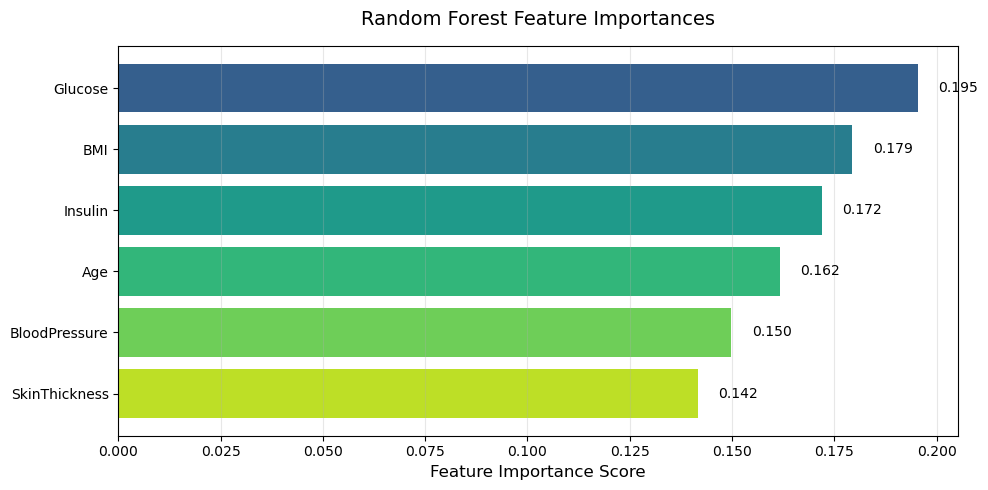


Clinical Interpretation:
------------------------------
1. Most Important: Glucose (19.5%) - Primary diabetes indicator
2. Second: BMI (17.9%) - Obesity correlation with diabetes
3. Third: Insulin (17.2%) - Insulin resistance measurement

Recommendation: Focus on Glucose monitoring for early detection


In [17]:
# CELL 14 – Feature Importance Analysis
print("Feature Importance Analysis:")
print("-" * 50)

# Random Forest Feature Importance
if hasattr(best_rf, "feature_importances_"):
    fi = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
    
    print("Random Forest Feature Importances:")
    print("-" * 30)
    for feature, importance in fi.items():
        print(f"  {feature:20s}: {importance:.4f} ({importance*100:.1f}%)")
    
    # Visualize
    plt.figure(figsize=(10, 5))
    colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(fi)))
    bars = plt.barh(range(len(fi)), fi.values[::-1], color=colors[::-1])
    plt.yticks(range(len(fi)), fi.index[::-1])
    plt.xlabel("Feature Importance Score", fontsize=12)
    plt.title("Random Forest Feature Importances", fontsize=14, pad=15)
    
    # Add value labels
    for i, (bar, val) in enumerate(zip(bars, fi.values[::-1])):
        plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, 
                f'{val:.3f}', va='center', fontsize=10)
    
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Clinical interpretation
    print("\nClinical Interpretation:")
    print("-" * 30)
    print(f"1. Most Important: Glucose ({fi['Glucose']*100:.1f}%) - Primary diabetes indicator")
    print(f"2. Second: BMI ({fi['BMI']*100:.1f}%) - Obesity correlation with diabetes")
    print(f"3. Third: Insulin ({fi['Insulin']*100:.1f}%) - Insulin resistance measurement")
    print(f"\nRecommendation: Focus on Glucose monitoring for early detection")
else:
    print("RandomForest has no feature_importances_ attribute.")